## DATS 2102 · Week 11 — Uncertainty & Error Visualization

This notebook demonstrates techniques for **communicating uncertainty** using home sales in **Ames, Iowa** (1,460 homes), the same data as Week 10.

- `GrLivArea`: above-ground living area, in square feet
- `SalePrice`: sale price, in dollars

- Libraries: Seaborn, Matplotlib, Plotly.
- Altair code is included as an **optional** section.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import altair as alt
from sklearn.linear_model import LinearRegression
from sklearn.utils import resample

# Enable Altair rendering in notebooks (choose one that fits your environment)
# alt.renderers.enable('default')  # Jupyter
# alt.renderers.enable('mimetype') # VS Code
# alt.data_transformers.disable_max_rows()  # if you hit row limits

sns.set_theme(style="whitegrid")

In [2]:
# Load the Ames data: from the data/ folder if you have it, otherwise from the course site
local = Path("data/ames.csv")
URL = "https://www.junjunyin.com/datascience/dats2102/weekly/week10/data/ames.csv"
df = pd.read_csv(local if local.exists() else URL)

df[["GrLivArea", "SalePrice"]].describe().round(0)

,GrLivArea,SalePrice
count,1460.0,1460.0
mean,1515.0,180921.0
std,525.0,79443.0
min,334.0,34900.0
25%,1130.0,129975.0
50%,1464.0,163000.0
75%,1777.0,214000.0
max,5642.0,755000.0


## 1. Seaborn: Mean ± 95% CI by binned `GrLivArea`

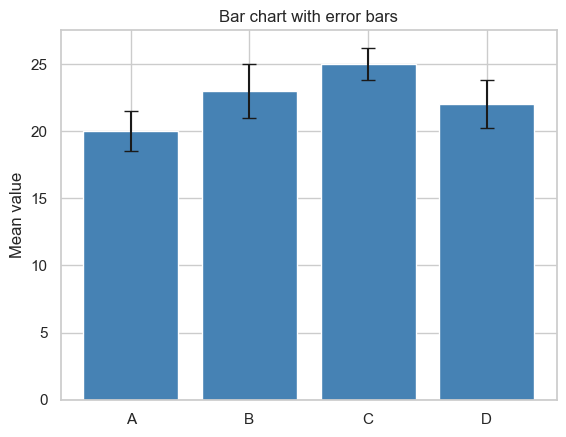

In [3]:
# Simulated means and standard errors
groups = ['A','B','C','D']
means = [20, 23, 25, 22]
se = [1.5, 2.0, 1.2, 1.8]

plt.bar(groups, means, yerr=se, capsize=5, color='steelblue')
plt.title('Bar chart with error bars')
plt.ylabel('Mean value')
plt.show()

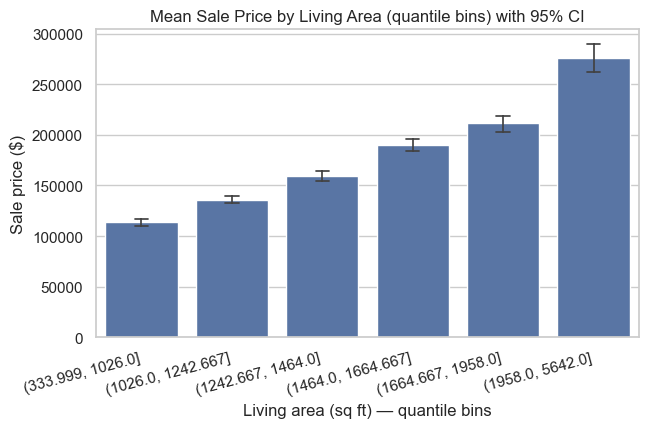

In [4]:
df1 = df.copy()
df1["area_bin"] = pd.qcut(df1["GrLivArea"], q=6, duplicates="drop")

plt.figure(figsize=(7,4))
sns.barplot(data=df1, x="area_bin", y="SalePrice", errorbar=('ci', 95), capsize=.15, err_kws={'linewidth': 1.25})
plt.xticks(rotation=15, ha="right")
plt.title("Mean Sale Price by Living Area (quantile bins) with 95% CI")
plt.xlabel("Living area (sq ft) — quantile bins")
plt.ylabel("Sale price ($)")
plt.show()

## 2. Seaborn: Regression with Confidence Band
Change `ci` and run the cell again: the band is wider at 95 than at 70.

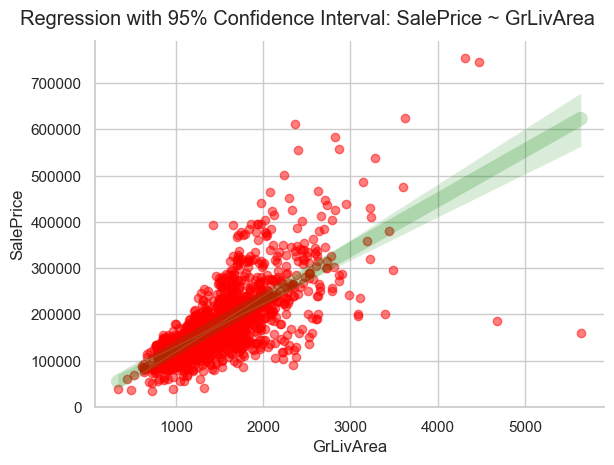

In [5]:
ci = 95

g = sns.lmplot(data=df, x="GrLivArea", y="SalePrice", height=4.5, aspect=1.4, ci=ci, scatter_kws={"alpha":0.5, "color":"red"}, line_kws={"color":"green", "alpha": 0.2, "linewidth":10})
g.fig.suptitle(f"Regression with {ci}% Confidence Interval: SalePrice ~ GrLivArea", y=1.03)
plt.show()

## 3. Altair (Optional): Layered Regression with 95% CI

> To run this section, install Altair + converter:
> `pip install altair vl-convert-python`

In [6]:
# Uncomment and run once if Altair is not installed, then restart the kernel
# %pip install altair vl-convert-python

In [7]:
import altair as alt
import pandas as pd
alt.data_transformers.disable_max_rows()
alt.renderers.enable('default')    # Jupyter
# alt.renderers.enable('mimetype') # VS Code

# Altair stores the data inside the chart, so pass only the columns we use
ames = df[["GrLivArea", "SalePrice"]]

base = alt.Chart(ames).mark_point(opacity=0.4).encode(
    x=alt.X('GrLivArea', title='Above-ground living area (sq ft)'),
    y=alt.Y('SalePrice', title='Sale price ($)'),
    tooltip=['GrLivArea','SalePrice']
)

reg_line = alt.Chart(ames).transform_regression('GrLivArea','SalePrice').mark_line(color='red', size=2)

(base + reg_line).properties(
    title='Altair: Regression Line (no CI)',
    width=500, height=300
)

alt.LayerChart(...)

In [8]:
import numpy as np
import pandas as pd
import altair as alt

alt.data_transformers.disable_max_rows()

# Bootstrap a linear fit to get a CI band, independent of Altair version
xs = np.linspace(df['GrLivArea'].min(), df['GrLivArea'].max(), 250)
B = 600  # number of bootstrap resamples

preds = np.empty((B, xs.size))
for b in range(B):
    sample = df.sample(len(df), replace=True, random_state=b)
    # simple linear fit y = slope*x + intercept
    slope, intercept = np.polyfit(sample['GrLivArea'].values, sample['SalePrice'].values, 1)
    preds[b, :] = slope*xs + intercept

band = pd.DataFrame({
    'GrLivArea': xs,
    'y_mean': preds.mean(axis=0),
    'y_low':  np.percentile(preds, 2.5, axis=0),
    'y_high': np.percentile(preds, 97.5, axis=0)
})

points = alt.Chart(ames).mark_point(opacity=0.35).encode(
    x=alt.X('GrLivArea', title='Above-ground living area (sq ft)'),
    y=alt.Y('SalePrice', title='Sale price ($)'),
    tooltip=['GrLivArea','SalePrice']
)

band_area = alt.Chart(band).mark_area(opacity=0.25).encode(
    x='GrLivArea',
    y='y_low',
    y2='y_high'
)

mean_line = alt.Chart(band).mark_line(color='red', size=2).encode(
    x='GrLivArea',
    y='y_mean'
)

(points + band_area + mean_line).properties(
    title='Altair: Regression with 95% Bootstrap CI (version-agnostic)',
    width=500, height=300
).interactive()

alt.LayerChart(...)

## 4. Box / Violin plots — distribution spread by binned `GrLivArea`

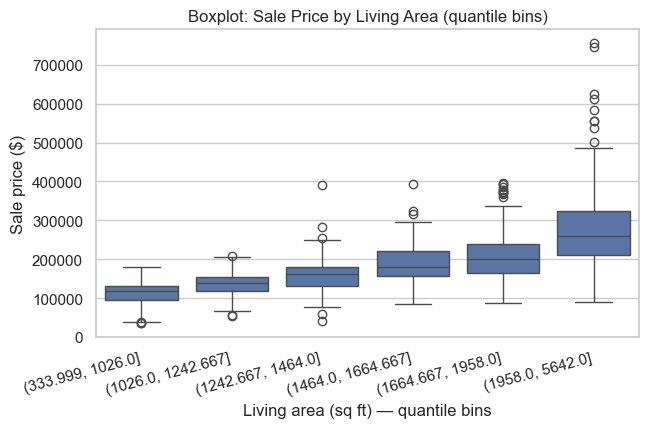

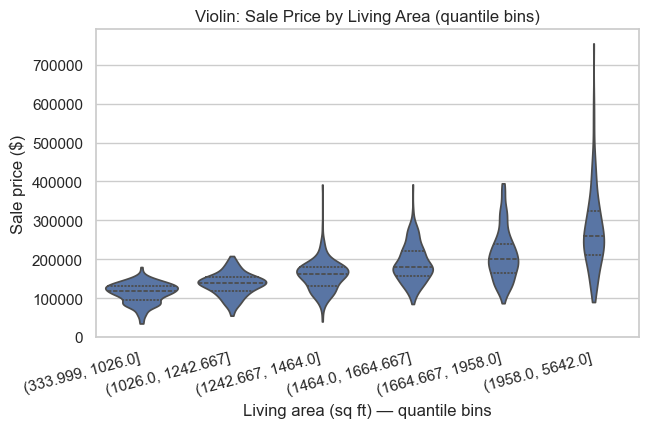

In [9]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df1, x="area_bin", y="SalePrice")
plt.xticks(rotation=15, ha="right")
plt.title("Boxplot: Sale Price by Living Area (quantile bins)")
plt.xlabel("Living area (sq ft) — quantile bins")
plt.ylabel("Sale price ($)")
plt.show()

plt.figure(figsize=(7,4))
sns.violinplot(data=df1, x="area_bin", y="SalePrice", inner="quartile", cut=0)
plt.xticks(rotation=15, ha="right")
plt.title("Violin: Sale Price by Living Area (quantile bins)")
plt.xlabel("Living area (sq ft) — quantile bins")
plt.ylabel("Sale price ($)")
plt.show()

## 5. Density curves & rug plots — `SalePrice`

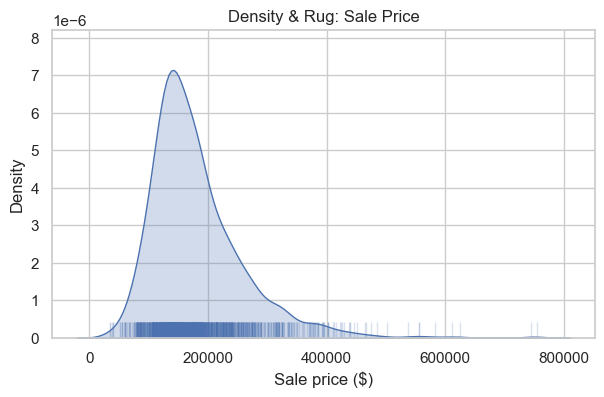

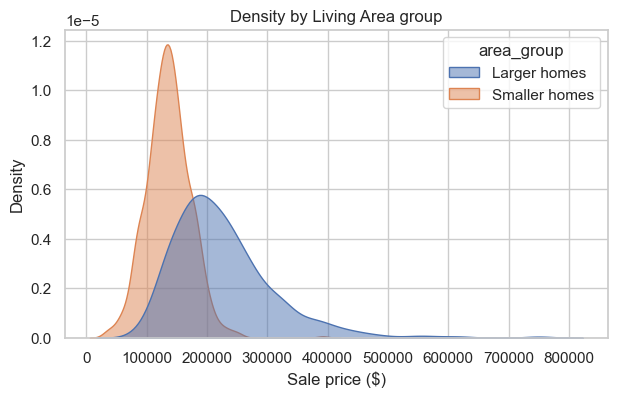

In [10]:
plt.figure(figsize=(7,4))
sns.kdeplot(data=df, x="SalePrice", fill=True)
sns.rugplot(data=df, x="SalePrice", alpha=0.2, height=0.05)
plt.title("Density & Rug: Sale Price")
plt.xlabel("Sale price ($)")
plt.ylabel("Density")
plt.show()

median_area = df["GrLivArea"].median()
df["area_group"] = np.where(df["GrLivArea"] >= median_area, "Larger homes", "Smaller homes")
plt.figure(figsize=(7,4))
sns.kdeplot(data=df, x="SalePrice", hue="area_group", fill=True, common_norm=False, alpha=0.5)
plt.title("Density by Living Area group")
plt.xlabel("Sale price ($)")
plt.ylabel("Density")
plt.show()

## 6. Opacity to suggest imprecision — alpha encodes uncertainty / density

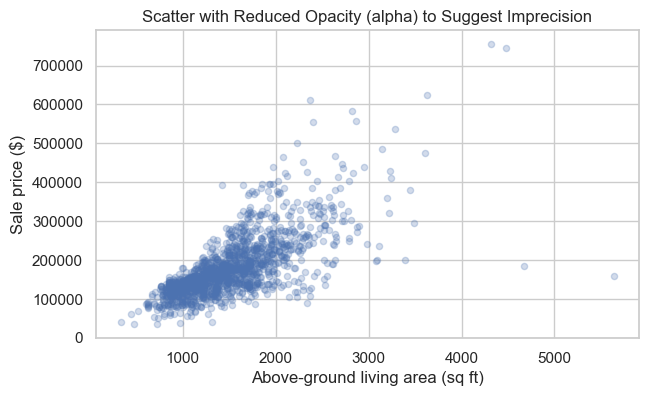

In [11]:
plt.figure(figsize=(7,4))
plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.25, s=20)
plt.title("Scatter with Reduced Opacity (alpha) to Suggest Imprecision")
plt.xlabel("Above-ground living area (sq ft)")
plt.ylabel("Sale price ($)")
plt.show()

## 7. Bootstrap: Distribution of Mean Sale Price

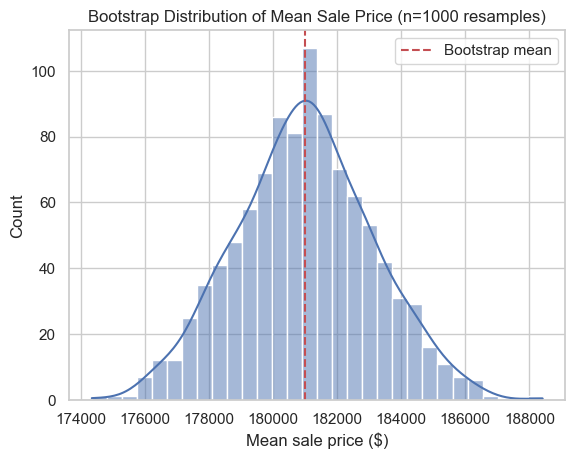

In [12]:
means = []
for i in range(1000):
    sample = resample(df["SalePrice"], random_state=i)
    means.append(sample.mean())

sns.histplot(means, kde=True, bins=30)
plt.axvline(np.mean(means), color='r', linestyle='--', label="Bootstrap mean")
plt.title("Bootstrap Distribution of Mean Sale Price (n=1000 resamples)")
plt.xlabel("Mean sale price ($)")
plt.legend()
plt.show()

## 8. Ensemble 'Spaghetti' of Bootstrap Fits (SalePrice ~ GrLivArea)
Each thin line is the regression fitted to one resample of the homes. Where the lines fan out, the fit is less certain. First in Matplotlib, then in Plotly.

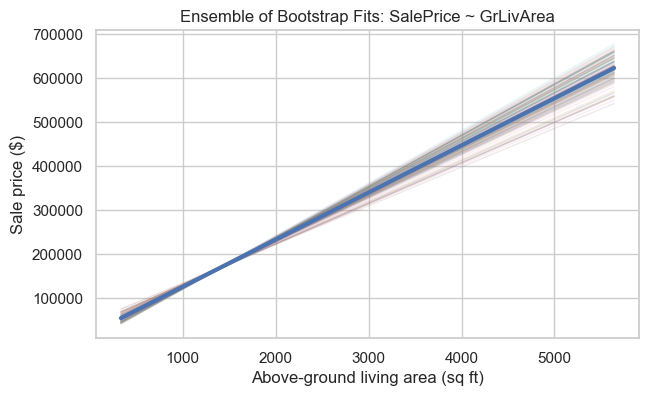

In [13]:
rng = np.random.default_rng(0)   # fixed seed, so the picture is the same on every run

X = df[["GrLivArea"]].values
y = df["SalePrice"].values
xs = np.linspace(df["GrLivArea"].min(), df["GrLivArea"].max(), 150).reshape(-1,1)

plt.figure(figsize=(7,4))
for i in range(100):
    idx = rng.choice(len(df), size=len(df), replace=True)
    Xi = X[idx]
    yi = y[idx]
    lr = LinearRegression().fit(Xi, yi)
    yhat = lr.predict(xs)
    plt.plot(xs, yhat, lw=1, alpha=0.15)
# Add mean fit
lr_full = LinearRegression().fit(X, y)
yhat_full = lr_full.predict(xs)
plt.plot(xs, yhat_full, lw=3)
plt.title("Ensemble of Bootstrap Fits: SalePrice ~ GrLivArea")
plt.xlabel("Above-ground living area (sq ft)")
plt.ylabel("Sale price ($)")
plt.show()

In [14]:
import plotly.graph_objects as go
import plotly.io as pio

# Load plotly.js from the web instead of storing a copy inside the notebook,
# which keeps the file small. In VS Code, use "vscode" here instead.
pio.renderers.default = "notebook_connected"

rng = np.random.default_rng(0)

X = df[["GrLivArea"]].values
y = df["SalePrice"].values
xs = np.linspace(df["GrLivArea"].min(), df["GrLivArea"].max(), 150).reshape(-1,1)

fig = go.Figure()
for i in range(80):
    idx = rng.choice(len(df), size=len(df), replace=True)
    Xi = X[idx]
    yi = y[idx]
    lr = LinearRegression().fit(Xi, yi)
    yhat = lr.predict(xs)
    fig.add_trace(go.Scatter(x=xs.flatten(), y=yhat, mode='lines', line=dict(width=1), opacity=0.2, showlegend=False))

lr_full = LinearRegression().fit(X, y)
yhat_full = lr_full.predict(xs)
fig.add_trace(go.Scatter(x=xs.flatten(), y=yhat_full, mode='lines', line=dict(width=3), name='Mean fit'))

fig.update_layout(title="Ensemble of Bootstrap Fits: SalePrice ~ GrLivArea",
                  xaxis_title="Above-ground living area (sq ft)",
                  yaxis_title="Sale price ($)",
                  template="plotly_white")
fig

### Key Takeaways
- Always **quantify** uncertainty (state SD, SE, 95% CI, credible interval, etc.).
- Use **shading/opacity** for bands; avoid clutter and overplotting.
- **Bootstrap** intervals often communicate sampling variability effectively.
- Interactivity (Altair/Plotly) helps audiences **explore** uncertainty.